<a href="https://colab.research.google.com/github/Jerefilms/DEEP-LEARNING/blob/main/samuel%20IAaa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

SAMUEL DAVID CELIS JEREMICHE
IA


Entrenando al agente con Q-Learning...
¡Entrenamiento completado!


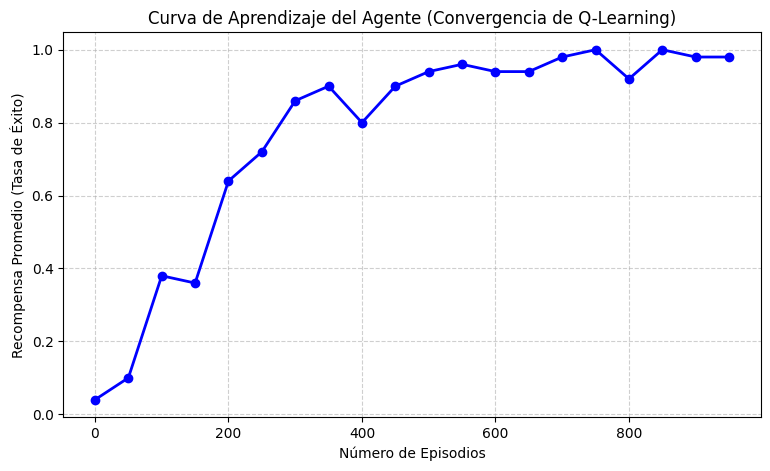


Tabla Q Final Aprendida (Estados x Acciones):
[[0.74 0.7  0.77 0.74]
 [0.74 0.   0.81 0.77]
 [0.77 0.86 0.77 0.81]
 [0.81 0.   0.76 0.77]
 [0.7  0.61 0.   0.74]
 [0.   0.   0.   0.  ]
 [0.   0.9  0.   0.81]
 [0.   0.   0.   0.  ]
 [0.   0.   0.68 0.7 ]
 [0.66 0.87 0.9  0.  ]
 [0.86 0.95 0.   0.86]
 [0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.9  0.95 0.86]
 [0.9  0.95 1.   0.9 ]
 [0.   0.   0.   0.  ]]


In [1]:

!pip install gymnasium -q

import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt


env = gym.make('FrozenLake-v1', is_slippery=False)

estado_dim = env.observation_space.n
accion_dim = env.action_space.n
q_table = np.zeros((estado_dim, accion_dim))


episodes = 1000          #numero de partidas de entreno
alpha = 0.8              #Tasa de aprendizaje
gamma = 0.95             #Factor de descuento
epsilon = 1.0            #Probabilidad inicial de exploración
epsilon_decay = 0.995    #Decaimiento de la exploración por episodio
min_epsilon = 0.01       #Lmite mínimo de exploración

recompensas_historial = []


print("Entrenando al agente con Q-Learning...")

for episode in range(episodes):
    estado, _ = env.reset()
    terminado = False
    truncado = False
    recompensa_total = 0

    while not (terminado or truncado):

        if np.random.uniform(0, 1) < epsilon:
            accion = env.action_space.sample()
        else:
            accion = np.argmax(q_table[estado, :])


        siguiente_estado, recompensa, terminado, truncado, _ = env.step(accion)


        q_valor_actual = q_table[estado, accion]
        max_q_siguiente = np.max(q_table[siguiente_estado, :])
        nuevo_q = q_valor_actual + alpha * (recompensa + gamma * max_q_siguiente - q_valor_actual)
        q_table[estado, accion] = nuevo_q

        estado = siguiente_estado
        recompensa_total += recompensa


    epsilon = max(min_epsilon, epsilon * epsilon_decay)
    recompensas_historial.append(recompensa_total)

print("¡Entrenamiento completado!")


bloques = 50
promedios = [np.mean(recompensas_historial[i:i+bloques]) for i in range(0, episodes, bloques)]

plt.figure(figsize=(9, 5))
plt.plot(range(0, episodes, bloques), promedios, marker='o', color='b', linewidth=2)
plt.title('Curva de Aprendizaje del Agente (Convergencia de Q-Learning)', fontsize=12)
plt.xlabel('Número de Episodios')
plt.ylabel('Recompensa Promedio (Tasa de Éxito)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


print("\nTabla Q Final Aprendida (Estados x Acciones):")
print(np.round(q_table, 2))